In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


In [2]:
PROJECT_ROOT = Path.cwd().parent

RESULTS_DIR = PROJECT_ROOT / "results"

METRICS_PATH = RESULTS_DIR / "evaluation_metrics.json"
REPORT_PATH = RESULTS_DIR / "classification_report.csv"
PREDICTIONS_PATH = RESULTS_DIR / "test_predictions.csv"

## Metrics

In [3]:
with METRICS_PATH.open("r", encoding="utf-8") as file:
    metrics = json.load(file)

metrics

{'accuracy': 0.8093333333333333,
 'precision': 0.7444444444444445,
 'recall': 0.7895622895622896,
 'f1': 0.7663398692810458,
 'roc_auc': 0.8849848744992234}

In [4]:
metrics_df = pd.DataFrame(
    {
        "Metric": list(metrics.keys()),
        "Value": list(metrics.values()),
    }
)

display(metrics_df)

,Metric,Value
0,accuracy,0.809333
1,precision,0.744444
2,recall,0.789562
3,f1,0.766340
4,roc_auc,0.884985


## Classification report

In [5]:
classification_report_df = pd.read_csv(
    REPORT_PATH,
    index_col=0,
)

display(classification_report_df)

,precision,recall,f1-score,support
real,0.856322,0.822296,0.838964,906.000000
fake,0.744444,0.789562,0.766340,594.000000
accuracy,0.809333,0.809333,0.809333,0.809333
macro avg,0.800383,0.805929,0.802652,1500.000000
weighted avg,0.812018,0.809333,0.810205,1500.000000


## Test predictions

In [6]:
predictions_df = pd.read_csv(
    PREDICTIONS_PATH,
)

display(
    predictions_df.head()
)

print(
    f"Test samples evaluated: {len(predictions_df):,}"
)

,id,text,image_path,label,image_url,sha256,phash,width,height,prediction,probability_real,probability_fake
0,d4nf8o,this reflection on a lake at night,images/test/d4nf8o.jpg,1,https://preview.redd.it/u8nxgffbksm31.jpg?widt...,f76a51c7ca7bbc7864fcf160464d31ae7609906f61be6d...,d1956f6e58d0052f,320.0,240.0,1,0.439417,0.560583
1,cl95oen,cutouts,images/test/cl95oen.jpg,0,http://i.imgur.com/DyOkG7x%2ejpg,1912e7e34a7c1ae9e53f52a104743b5e43094ff60d01fc...,f6edc23091fb8270,640.0,640.0,0,0.989492,0.010508
2,byjwzn,this underground style map of edinburgh pubs,images/test/byjwzn.jpg,1,https://preview.redd.it/ilby4yunvb331.jpg?widt...,c8a1701008e6f368b33a75e8fa4d4ac5eaf225a90afbc1...,83c7cfdb2a047ce0,320.0,240.0,0,0.534807,0.465193
3,cv61bzg,stay back,images/test/cv61bzg.jpg,0,http://i.imgur.com/mO6zSPn.jpg,cc687de9bd5d232609b6f005adae102d6239abcddd93d3...,f9f8911c5a7389c4,640.0,640.0,0,0.966329,0.033671
4,ck64sg1,other discussions,images/test/ck64sg1.jpg,0,http://i.imgur.com/Mje1CLR%2ejpg,b6478ef29903d0001172b209530a222e03465406b127b9...,a2dbfc84b321a93a,910.0,600.0,0,0.991920,0.008080


Test samples evaluated: 1,500


## Sanity checks

In [7]:
assert len(predictions_df) == 1500

assert {
    "prediction",
    "probability_real",
    "probability_fake",
}.issubset(
    predictions_df.columns
)

assert predictions_df["prediction"].isin([0, 1]).all()

assert (
    (predictions_df["probability_real"] >= 0)
    & (predictions_df["probability_real"] <= 1)
).all()

assert (
    (predictions_df["probability_fake"] >= 0)
    & (predictions_df["probability_fake"] <= 1)
).all()

assert (
    abs(
        predictions_df["probability_real"]
        + predictions_df["probability_fake"]
        - 1
    ).max()
    < 1e-5
)

print("All evaluation sanity checks passed.")

All evaluation sanity checks passed.


## Confusion matrix

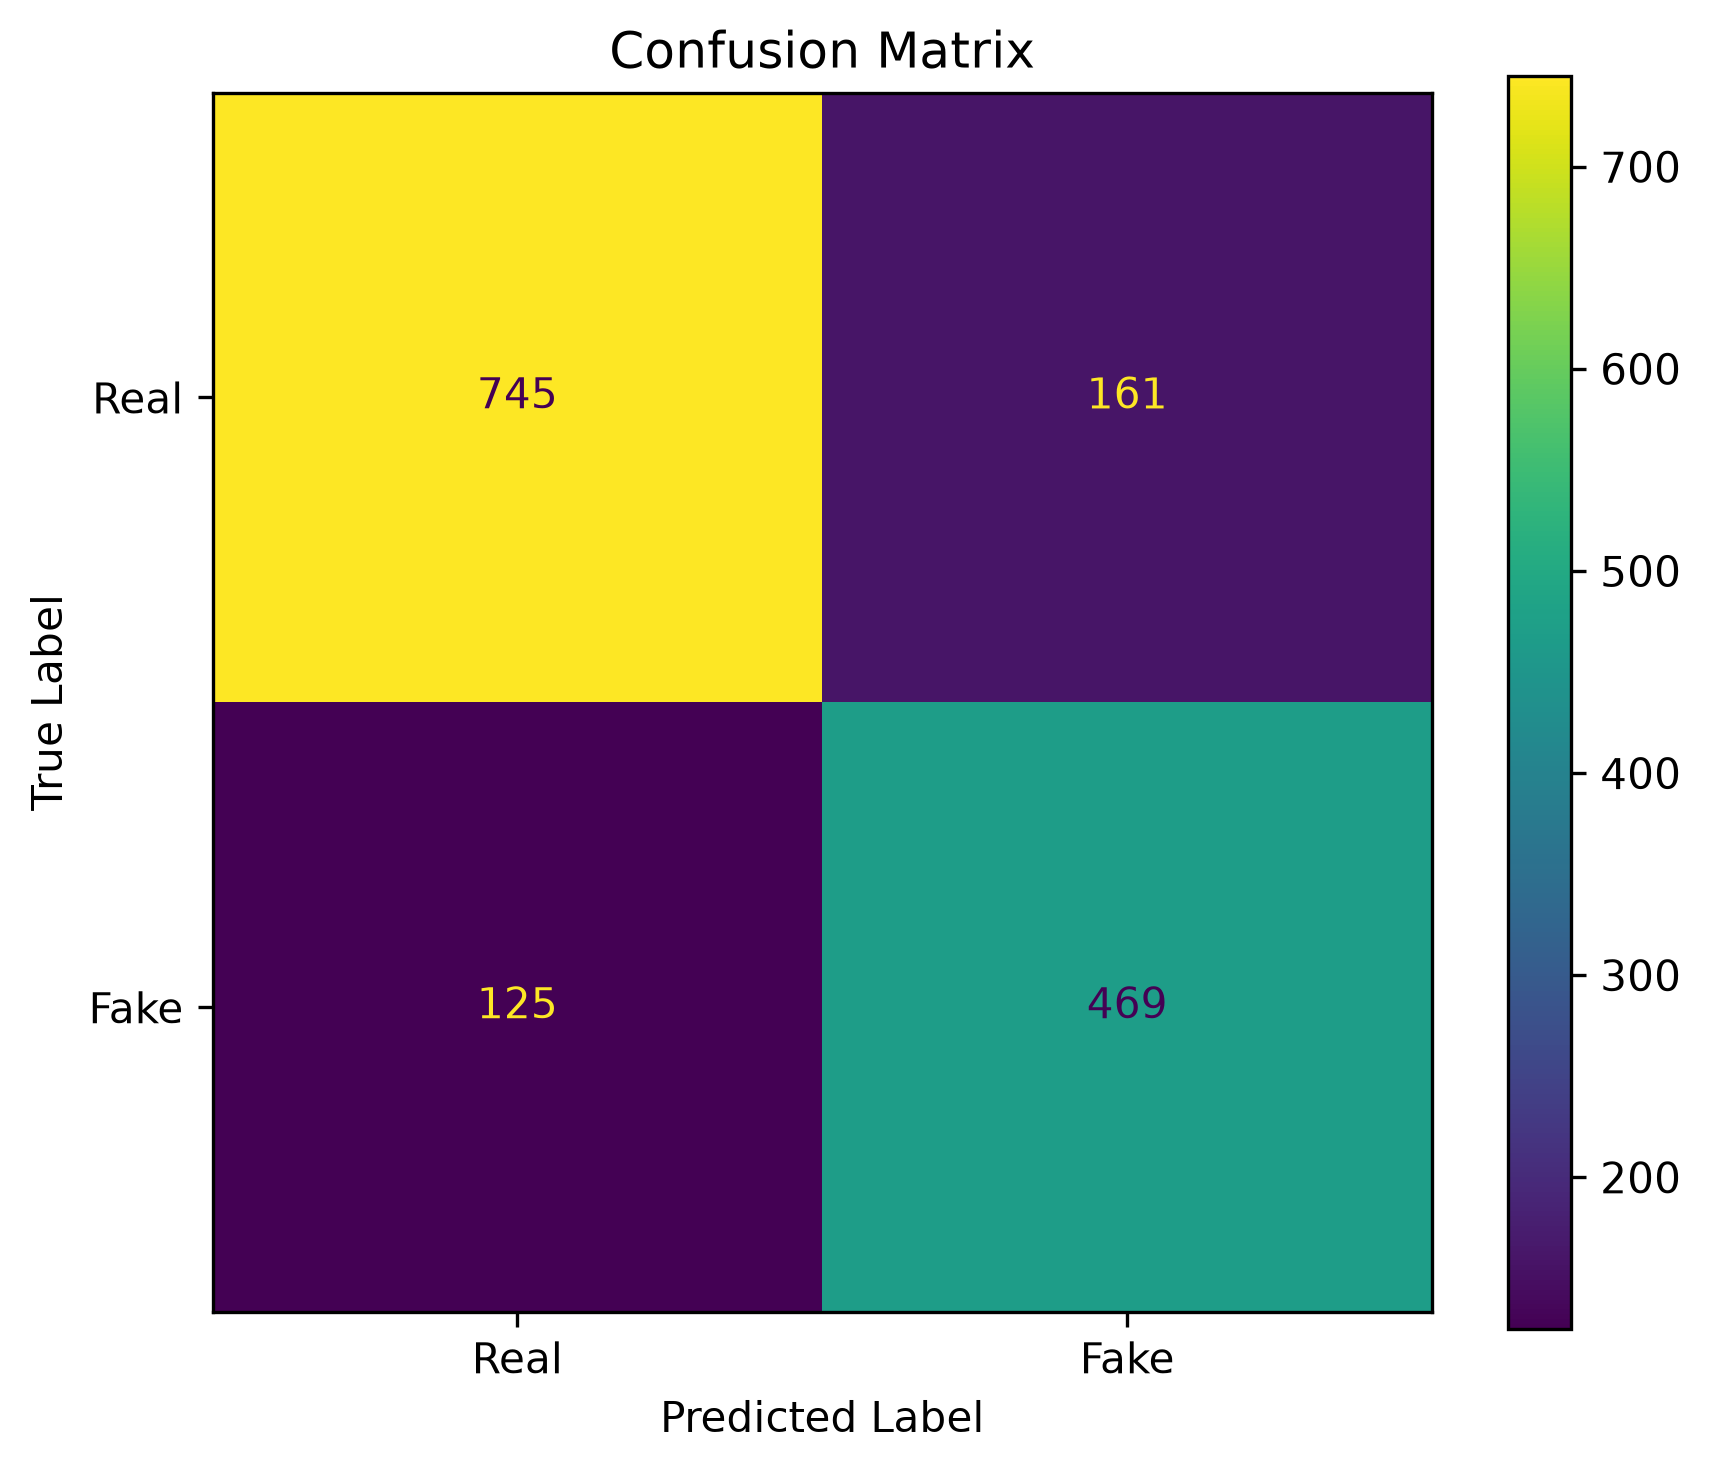

In [8]:
from IPython.display import Image, display

display(
    Image(
        filename=str(
            RESULTS_DIR / "confusion_matrix.png"
        )
    )
)

## ROC curve

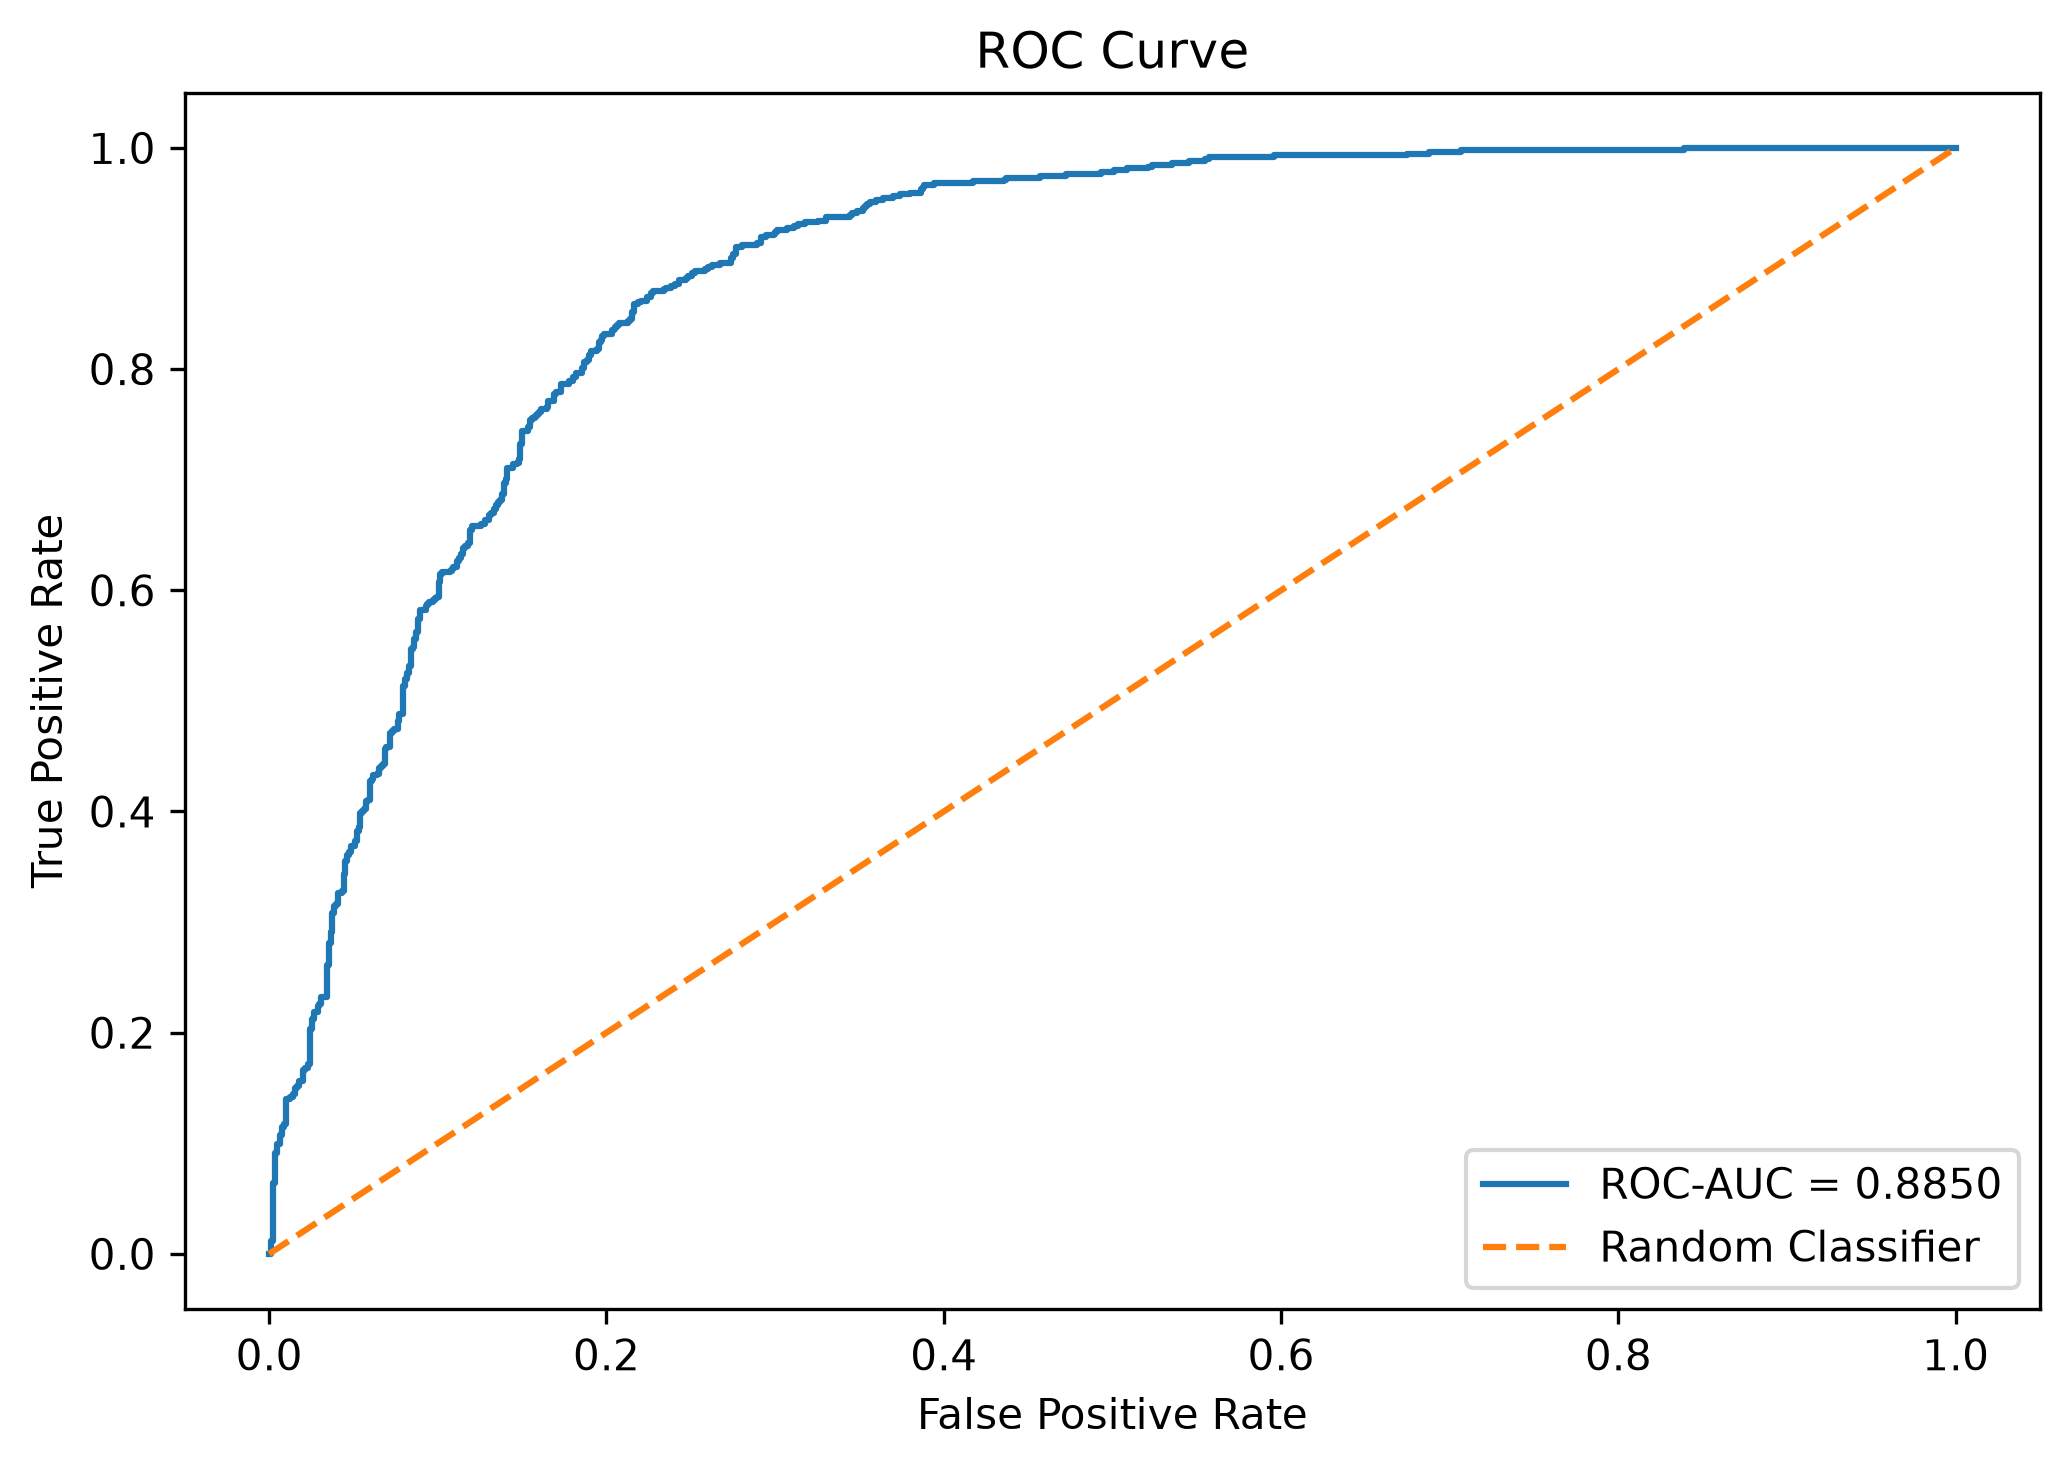

In [9]:
display(
    Image(
        filename=str(
            RESULTS_DIR / "roc_curve.png"
        )
    )
)